**NBA Elo EDA · Part 4 of 4.** Group comparisons and multivariate EDA.

**Dataset:** NBA All Elo (NBA & ABA game results with Elo ratings), [FiveThirtyEight](https://github.com/fivethirtyeight/data/tree/master/nba-elo), CC BY 4.0. Parts: [1](01_data_quality.ipynb) · [2](02_distributions_outliers.ipynb) · [3](03_bivariate.ipynb) · [4](04_groups_multivariate.ipynb)

# Part 4 — Group Comparisons & Multivariate EDA

**Goal.** Parts 1–3 described the variables and pairs of variables. This part asks whether those patterns hold **inside groups**, and what changes when several variables are considered together.

**Expectations written before the analysis** (based on Parts 1–3):

| Question | Expectation |
|---|---|
| Do playoff games score differently from regular-season games? | Slightly fewer points in the playoffs (stronger defence), with heavily overlapping distributions. |
| Which eras differ most? | 1947–54 against everything else: Part 3 showed the shot-clock jump. |
| Does `pts`–`opp_pts` survive stratification? | Yes, but weaker: Part 3 suggested part of it comes from differences between eras. |
| Is home win rate associated with season type? | Yes, but Part 3 showed that the playoff home team is often the better team, so part of it should be team strength. |
| What will PCA find? | One axis for scoring level and one for team strength or time. |

## 0. Setup and data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

%matplotlib inline

SEED = 42
ALPHA = 0.05

# Project root: the parent folder when the notebook runs from notebooks/, otherwise the current folder.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "results" / "figures"
TAB_DIR = ROOT / "results" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# Colours: a fixed categorical order (checked for colour-blind separation), quiet grid and axes.
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.labelsize": 10, "axes.grid": True, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "font.size": 10,
})


def save_table(table, name):
    """Save a result table to results/tables and return it for display."""
    table.to_csv(TAB_DIR / f"{name}.csv")
    return table


def save_fig(fig, name):
    """Save a figure to results/figures."""
    fig.savefig(FIG_DIR / f"{name}.png")

In [2]:
# Same dataset and same loading logic as Parts 1–3:
# use a local copy if there is one, otherwise download from the public source.
DATA_URL = "https://raw.githubusercontent.com/fivethirtyeight/data/master/nba-elo/nbaallelo.csv"
CACHE_PATH = ROOT / "data" / "nbaallelo.csv"

if CACHE_PATH.exists():
    df = pd.read_csv(CACHE_PATH)
else:
    df = pd.read_csv(DATA_URL)
    CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(CACHE_PATH, index=False)

print("Raw file:", df.shape)
df[["game_id", "year_id", "lg_id", "is_playoffs", "team_id", "pts", "opp_id", "opp_pts", "elo_i", "opp_elo_i",
    "game_location", "game_result", "_iscopy"]].head()

Raw file: (110902, 23)


,game_id,year_id,lg_id,is_playoffs,team_id,pts,opp_id,opp_pts,elo_i,opp_elo_i,game_location,game_result,_iscopy
0,194611010TRH,1947,NBA,0,TRH,66,NYK,68,1300.0000,1300.0000,H,L,0
1,194611010TRH,1947,NBA,0,NYK,68,TRH,66,1300.0000,1300.0000,A,W,1
2,194611020CHS,1947,NBA,0,CHS,63,NYK,47,1300.0000,1306.7233,H,W,0
3,194611020CHS,1947,NBA,0,NYK,47,CHS,63,1306.7233,1300.0000,A,L,1
4,194611020DTF,1947,NBA,0,DTF,33,WSC,50,1300.0000,1300.0000,H,L,0


### Unit of analysis and variables

As in Part 3, each game appears twice in the raw file, so I keep the home team's row (`_iscopy == 0`). This matters most for the Chi-Square test: counting a game twice would inflate χ² by a factor of two and break the independence of observations.

- **`total_pts = pts + opp_pts`** is the main numerical variable in Sections 1–2. It describes the *game*, so it does not need the double-counted team rows used in Part 3.
- `margin`, `elo_diff`, `era` and `season_type` are defined exactly as in Part 3.
- **The 1972 forfeit (2–0) is removed**, following the Part 2 decision to exclude it from analyses of typical scoring. Part 3 showed that it has no measurable effect on correlations.
- Home-court tests (Section 4) also leave out the 13 games coded as neutral site, where no team was truly at home.

In [3]:
# One row per game: keep the home team's row (the same rule as in A3). The raw file is never changed.
games = df[df["_iscopy"] == 0].copy()
n_raw_games = len(games)

# Forfeit from A2: "2-0" is an administrative result, not basketball, so it is removed.
is_forfeit = games["notes"].fillna("").str.contains("forfeit", case=False)
print("Forfeit removed:", games.loc[is_forfeit, ["date_game", "team_id", "pts", "opp_id", "opp_pts", "notes"]].to_dict("records"))
games = games[~is_forfeit].copy()

# Derived variables
games["total_pts"] = games["pts"] + games["opp_pts"]
games["margin"] = games["pts"] - games["opp_pts"]
games["elo_diff"] = games["elo_i"] - games["opp_elo_i"]
games["home_result"] = np.where(games["margin"] > 0, "Home win", "Home loss")
games["season_type"] = np.where(games["is_playoffs"] == 1, "Playoffs", "Regular season")

ERA_BINS = [1946, 1954, 1969, 1979, 1994, 2009]
ERA_LABELS = ["1947-54", "1955-69", "1970-79", "1980-94", "1995-2009"]
games["era"] = pd.cut(games["year_id"], bins=ERA_BINS, labels=ERA_LABELS)
ERA_COLORS = dict(zip(ERA_LABELS, [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]))

# Checks that the rest of the notebook relies on
assert games["game_id"].is_unique
assert (games["margin"] != 0).all()
assert games[["total_pts", "elo_diff", "era"]].notna().all().all()

# Home-court questions use only games actually coded as played at home.
home_games = games[games["game_location"] == "H"].copy()

print(f"Games: {n_raw_games:,} -> {len(games):,} after removing the forfeit; {len(home_games):,} with a true home team")
print("Games with elo_diff exactly 0:", (games["elo_diff"] == 0).sum())
games[["date_game", "era", "season_type", "lg_id", "team_id", "pts", "opp_id", "opp_pts", "total_pts", "margin",
       "elo_diff", "home_result"]].sample(5, random_state=SEED)

Forfeit removed: [{'date_game': '10/26/1972', 'team_id': 'VIR', 'pts': 2, 'opp_id': 'DNR', 'opp_pts': 0, 'notes': 'at Richmond VA; forfeit to VIR'}]
Games: 55,451 -> 55,450 after removing the forfeit; 55,437 with a true home team
Games with elo_diff exactly 0: 8


,date_game,era,season_type,lg_id,team_id,pts,opp_id,opp_pts,total_pts,margin,elo_diff,home_result
99620,3/5/2005,1995-2009,Regular season,NBA,LAC,89,DEN,105,194,-16,-42.3403,Home loss
107187,2/5/2008,1995-2009,Regular season,NBA,NJN,90,LAL,105,195,-15,-247.4574,Home loss
33708,4/23/1975,1970-79,Playoffs,NBA,BUF,102,WSB,96,198,6,-101.4774,Home win
33519,3/31/1975,1970-79,Regular season,ABA,KEN,103,SAA,88,191,15,54.6862,Home win
109216,12/22/2008,1995-2009,Regular season,NBA,SAS,101,SAC,85,186,16,231.7552,Home win


In [4]:
def tukey_outliers(values):
    """Mask of values outside the 1.5 x IQR fences of this group."""
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)


def group_summary(data, group, value):
    """Count, mean, median, spread and outlier count for every group."""
    rows = {}
    for name, g in data.groupby(group, observed=True)[value]:
        q1, q3 = g.quantile([0.25, 0.75])
        rows[name] = {"count": len(g), "mean": g.mean(), "median": g.median(), "std": g.std(),
                      "Q1": q1, "Q3": q3, "IQR": q3 - q1, "min": g.min(), "max": g.max(),
                      "outliers": int(tukey_outliers(g).sum()), "outliers %": 100 * tukey_outliers(g).mean()}
    out = pd.DataFrame(rows).T
    out.index.name = group
    return out


def box_by_group(ax, data, group, value, order, colors):
    """Boxplot with one colour per group and the sample size in the axis label."""
    series = [data.loc[data[group] == level, value] for level in order]
    parts = ax.boxplot(series, patch_artist=True, widths=0.55,
                       medianprops=dict(color=INK, linewidth=1.6),
                       whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
                       flierprops=dict(marker="o", markersize=2.5, markerfacecolor=MUTED,
                                       markeredgecolor="none", alpha=0.35))
    for patch, level in zip(parts["boxes"], order):
        patch.set(facecolor=colors[level], edgecolor="white", alpha=0.85)
    ax.set_xticks(range(1, len(order) + 1))
    ax.set_xticklabels([f"{level}\nn = {len(s):,}" for level, s in zip(order, series)])
    ax.grid(axis="x", visible=False)

## 1. Compare Groups: total points by season type

**Numerical variable:** `total_pts`. **Categorical variable:** `season_type` (regular season, playoffs).

Why this choice: Part 3 compared the *margin* between these groups and found almost no difference. How many points are scored is a different question, and it connects directly to the stratification in Section 3.

In [5]:
summary_season = save_table(group_summary(games, "season_type", "total_pts"), "summary_total_pts_by_season_type")
summary_season.round(2)

,count,mean,median,std,Q1,Q3,IQR,min,max,outliers,outliers %
season_type,,,,,,,,,,,
Playoffs,3466.0,202.24,202.0,26.92,184.0,221.0,37.0,107.0,304.0,26.0,0.75
Regular season,51984.0,206.74,207.0,27.07,189.0,225.0,36.0,37.0,370.0,585.0,1.13


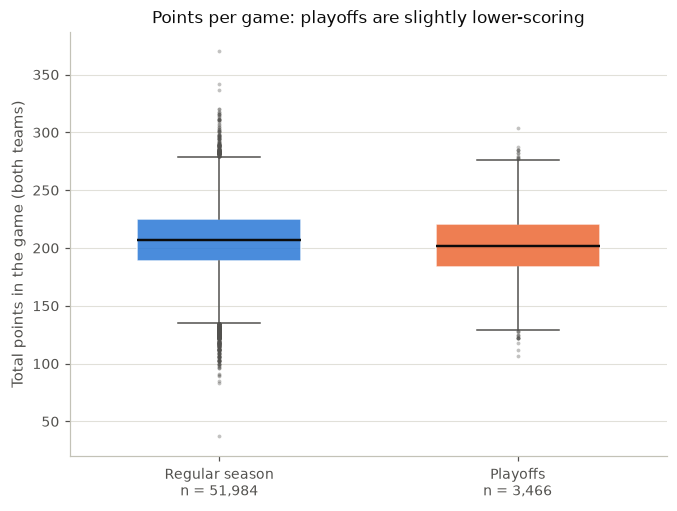

        date_game     season_type team_id  pts opp_id  opp_pts  total_pts
3190   11/22/1950  Regular season     MNL   18    FTW       19         37
4       11/2/1946  Regular season     DTF   33    WSC       50         83
50095  12/13/1983  Regular season     DEN  184    DET      186        370
32881   2/14/1975  Regular season     SDA  176    NYA      166        342
1101    3/30/1948        Playoffs     PHW   51    STB       56        107
68934   5/11/1992        Playoffs     PHO  151    POR      153        304

Mean gap (playoffs - regular): -4.50 points = -0.17 standard deviations


In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
box_by_group(ax, games, "season_type", "total_pts", ["Regular season", "Playoffs"],
             {"Regular season": BLUE, "Playoffs": ORANGE})
ax.set_title("Points per game: playoffs are slightly lower-scoring")
ax.set_xlabel("")
ax.set_ylabel("Total points in the game (both teams)")
save_fig(fig, "fig1_total_pts_by_season_type")
plt.show()

# The most extreme games of each group
extreme = pd.concat([games.nsmallest(2, "total_pts"), games.nlargest(2, "total_pts"),
                     games[games["is_playoffs"] == 1].nsmallest(1, "total_pts"),
                     games[games["is_playoffs"] == 1].nlargest(1, "total_pts")])
print(extreme[["date_game", "season_type", "team_id", "pts", "opp_id", "opp_pts", "total_pts"]].to_string())

gap = summary_season.loc["Playoffs", "mean"] - summary_season.loc["Regular season", "mean"]
pooled_std = games["total_pts"].std()
print(f"\nMean gap (playoffs - regular): {gap:.2f} points = {gap / pooled_std:.2f} standard deviations")

**Interpretation.**

- **Typical values:** the median game has 207 points in the regular season and 202 in the playoffs; the means tell the same story (206.7 vs 202.2). Mean and median almost coincide in both groups, so the distributions are nearly symmetric. This matches my expectation about direction.
- **Spread:** practically identical (SD 27.1 vs 26.9, IQR 36 vs 37). The groups differ in level, not in variability.
- **Unusual observations:** the regular season holds the extremes: the 37-point game (Minneapolis 18 – Fort Wayne 19, 1950) and the 370-point triple-overtime game (Denver 184 – Detroit 186, 1983). These extremes are partly a matter of sample size, since there are 15 times more regular-season games. Tukey outliers are rare in both groups (1.13% vs 0.75%), and all the games named here are genuine, so I keep them.
- **Size of the difference:** the gap is 4.5 points, or just 0.17 standard deviations. The boxes overlap almost completely. Knowing that a game is a playoff game says very little about its score.

## 2. Compare More Than Two Groups: total points by era

**Same numerical variable, new categorical variable:** `era`, five groups defined in Part 3 from scoring trends and rule changes.

In [7]:
summary_era = save_table(group_summary(games, "era", "total_pts"), "summary_total_pts_by_era")
summary_era.round(2)

,count,mean,median,std,Q1,Q3,IQR,min,max,outliers,outliers %
era,,,,,,,,,,,
1947-54,2994.0,158.56,158.0,22.33,144.0,173.0,29.0,37.0,248.0,34.0,1.14
1955-69,6664.0,222.60,223.0,24.12,207.0,239.0,32.0,119.0,316.0,48.0,0.72
1970-79,11212.0,218.30,218.0,21.95,203.0,233.0,30.0,149.0,342.0,88.0,0.78
1980-94,15991.0,215.14,214.0,21.67,201.0,229.0,28.0,133.0,370.0,182.0,1.14
1995-2009,18589.0,193.79,193.0,20.77,180.0,207.0,27.0,121.0,318.0,187.0,1.01


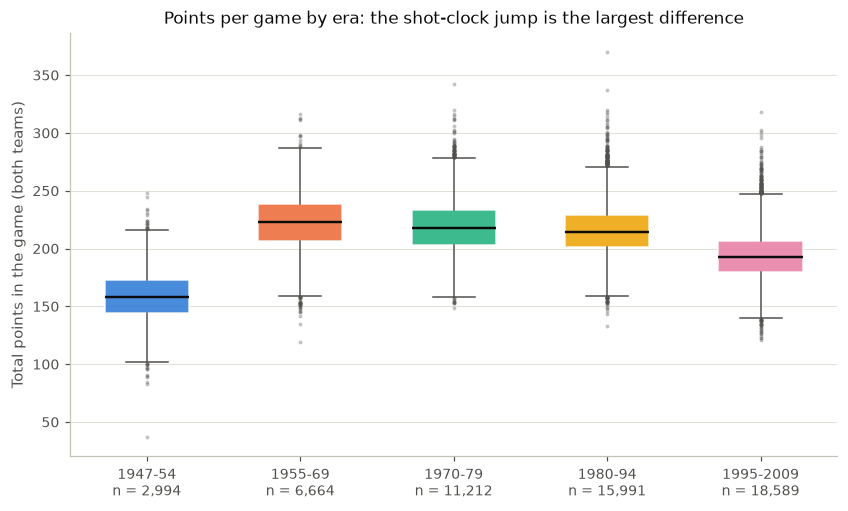

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
box_by_group(ax, games, "era", "total_pts", ERA_LABELS, ERA_COLORS)
ax.set_title("Points per game by era: the shot-clock jump is the largest difference")
ax.set_xlabel("")
ax.set_ylabel("Total points in the game (both teams)")
save_fig(fig, "fig2_total_pts_by_era")
plt.show()

In [9]:
# Which eras differ most? Difference in medians and in standard-deviation units (Cohen's d) for every pair.
rows = []
for i, a in enumerate(ERA_LABELS):
    for b in ERA_LABELS[i + 1:]:
        xa, xb = games.loc[games["era"] == a, "total_pts"], games.loc[games["era"] == b, "total_pts"]
        pooled = np.sqrt(((len(xa) - 1) * xa.var() + (len(xb) - 1) * xb.var()) / (len(xa) + len(xb) - 2))
        rows.append({"pair": f"{a} vs {b}", "median difference": xb.median() - xa.median(),
                     "Cohen's d": (xb.mean() - xa.mean()) / pooled})
pairs_era = save_table(pd.DataFrame(rows).set_index("pair").sort_values("Cohen's d", key=np.abs, ascending=False),
                       "era_pairwise_differences")

# Eta squared: share of all variation in total points that lies between eras
grand_mean = games["total_pts"].mean()
ss_between = games.groupby("era", observed=True)["total_pts"].apply(lambda s: len(s) * (s.mean() - grand_mean) ** 2).sum()
eta_squared = ss_between / ((games["total_pts"] - grand_mean) ** 2).sum()
print(f"Eta squared (share of variation between eras): {eta_squared:.3f}")
pairs_era.round(2)

Eta squared (share of variation between eras): 0.353


,median difference,Cohen's d
pair,,
1947-54 vs 1955-69,65.0,2.72
1947-54 vs 1970-79,60.0,2.71
1947-54 vs 1980-94,56.0,2.60
1947-54 vs 1995-2009,35.0,1.68
1955-69 vs 1995-2009,-30.0,-1.33
1970-79 vs 1995-2009,-25.0,-1.16
1980-94 vs 1995-2009,-21.0,-1.01
1955-69 vs 1980-94,-9.0,-0.33
1955-69 vs 1970-79,-5.0,-0.19


**Which groups differ most?** 1947–54 against everything else, as expected. The largest pairs are 1947–54 vs 1955–69 (median +65 points, d = 2.72) and vs 1970–79 (+60, d = 2.71). For 1947–54 and 1955–69 the boxes do not overlap at all: the upper quartile of the first (173) lies below the lower quartile of the second (207). The second clear break is 1995–2009, about 21–30 points below the three previous eras (|d| from 1.0 to 1.3). In contrast, 1955–69, 1970–79 and 1980–94 are close to one another (|d| ≤ 0.33).

Era explains **35%** of all variation in total points (η² = 0.353), which is large compared with the two-group comparison above. Spread is similar across eras (IQR 27–32); the differences are mostly in location.

In [10]:
# Influence of sample size and outliers
rng = np.random.default_rng(SEED)
rows = {}
for era in ERA_LABELS:
    s = games.loc[games["era"] == era, "total_pts"]
    boot = [rng.choice(s.values, len(s)).mean() for _ in range(1000)]
    kept = s[~tukey_outliers(s)]
    small = [rng.choice(s.values, 50, replace=False).mean() for _ in range(1000)]
    rows[era] = {"n": len(s), "mean": s.mean(),
                 "95% CI low": np.percentile(boot, 2.5), "95% CI high": np.percentile(boot, 97.5),
                 "CI width": np.percentile(boot, 97.5) - np.percentile(boot, 2.5),
                 "mean without outliers": kept.mean(), "shift from outliers": s.mean() - kept.mean(),
                 "median without outliers": kept.median(), "median": s.median(),
                 "SD of mean if n = 50": np.std(small)}
sensitivity = save_table(pd.DataFrame(rows).T, "era_sample_size_and_outliers")

print(f"Pooled mean of all games:            {grand_mean:.1f}")
print(f"Unweighted mean of the 5 era means:  {summary_era['mean'].mean():.1f}")
print("Season means inside each era (min-max):")
season_means = games.groupby("year_id")["total_pts"].mean()
for era, lo, hi in zip(ERA_LABELS, ERA_BINS[:-1], ERA_BINS[1:]):
    part = season_means.loc[lo + 1:hi]
    print(f"  {era}: {part.min():.1f} - {part.max():.1f}")
sensitivity.round(2)

Pooled mean of all games:            206.5
Unweighted mean of the 5 era means:  201.7
Season means inside each era (min-max):
  1947-54: 135.8 - 168.0
  1955-69: 186.7 - 236.6
  1970-79: 209.6 - 230.0
  1980-94: 202.0 - 222.2
  1995-2009: 182.5 - 202.6


,n,mean,95% CI low,95% CI high,CI width,mean without outliers,shift from outliers,median without outliers,median,SD of mean if n = 50
1947-54,2994.0,158.56,157.73,159.35,1.62,158.47,0.09,158.0,158.0,3.14
1955-69,6664.0,222.60,222.03,223.18,1.15,222.85,-0.25,223.0,223.0,3.50
1970-79,11212.0,218.30,217.91,218.70,0.79,217.88,0.42,217.0,218.0,3.10
1980-94,15991.0,215.14,214.78,215.48,0.70,214.63,0.51,214.0,214.0,3.01
1995-2009,18589.0,193.79,193.47,194.07,0.60,193.35,0.43,193.0,193.0,3.05


**Influence of sample size and outliers.**

- **Sample size does not threaten the era means.** Even the smallest group (2,994 games) has a 95% CI only 1.6 points wide, while the main gaps are tens of points. The small differences would be less stable with little data: at n = 50 a sample mean varies by about 3 points, which is the size of the 3.2-point gap between 1970–79 and 1980–94. With the real sample sizes that gap is measurable, but it is small in practical terms (d = −0.14).
- **Group size does shape the pooled average.** The average over all games (206.5) is 4.8 points higher than the unweighted mean of the five eras (201.7), because the first era is small and low-scoring.
- **Outliers barely matter.** Removing Tukey outliers within each era moves the mean by at most 0.51 points and the median by at most 1 point. Even the most extreme games (37 and 370 points) cannot move a mean computed over thousands of games.
- **Era is a coarse grouping.** Season means inside 1955–69 range from 186.7 to 236.6, so this era's wider spread (the largest SD, 24.1) partly reflects a trend inside the group, not only game-to-game variation.

## 3. Stratification and Confounding

**Relationship reused from Part 3:** `pts` vs `opp_pts`. Part 3 found r ≈ 0.64 and called its cause a shared "game environment". Here I measure how much of the relationship is caused by a specific candidate confounder.

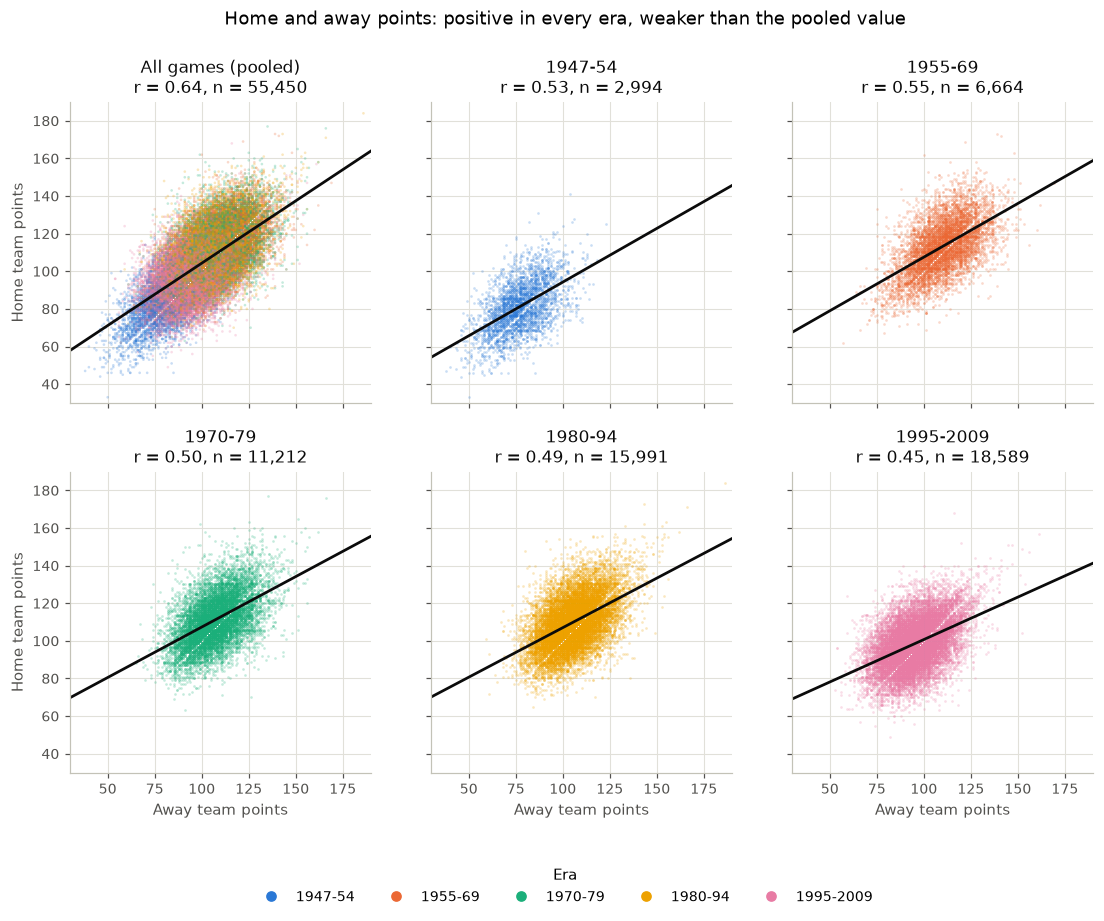

,n games,Pearson r,r CI low,r CI high,Spearman rho,slope (home pts per away pt),mean home pts,mean away pts
All games (pooled),55450.0,0.636,0.631,0.641,0.610,0.663,105.162,101.300
1947-54,2994.0,0.527,0.501,0.553,0.499,0.571,81.270,77.286
1955-69,6664.0,0.552,0.535,0.568,0.536,0.571,113.001,109.595
1970-79,11212.0,0.502,0.488,0.515,0.486,0.537,111.178,107.122
1980-94,15991.0,0.489,0.477,0.501,0.463,0.527,109.826,105.315
1995-2009,18589.0,0.445,0.434,0.457,0.417,0.451,98.559,95.228


In [11]:
def fisher_ci(r, n):
    """95% confidence interval of a correlation (Fisher z)."""
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
    return np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)


rows = {}
for name, g in [("All games (pooled)", games)] + [(e, games[games["era"] == e]) for e in ERA_LABELS]:
    r = g["pts"].corr(g["opp_pts"])
    low, high = fisher_ci(r, len(g))
    rows[name] = {"n games": len(g), "Pearson r": r, "r CI low": low, "r CI high": high,
                  "Spearman rho": g["pts"].rank().corr(g["opp_pts"].rank()),
                  "slope (home pts per away pt)": np.polyfit(g["opp_pts"], g["pts"], 1)[0],
                  "mean home pts": g["pts"].mean(), "mean away pts": g["opp_pts"].mean()}
strata = save_table(pd.DataFrame(rows).T, "pts_vs_opp_pts_by_era")

fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharex=True, sharey=True)
xs = np.array([30, 190])
for ax, (name, g) in zip(axes.flat, [("All games (pooled)", games)] + [(e, games[games["era"] == e]) for e in ERA_LABELS]):
    # On the pooled panel colour shows the era, so that the stacking along the diagonal is visible.
    if name.startswith("All"):
        shuffled = g.sample(frac=1, random_state=SEED)
        ax.scatter(shuffled["opp_pts"], shuffled["pts"], s=3, alpha=0.25, linewidths=0,
                   c=shuffled["era"].astype(str).map(ERA_COLORS), rasterized=True)
    else:
        ax.scatter(g["opp_pts"], g["pts"], s=3, alpha=0.25, linewidths=0, color=ERA_COLORS[name], rasterized=True)
    slope, intercept = np.polyfit(g["opp_pts"], g["pts"], 1)
    ax.plot(xs, intercept + slope * xs, color=INK, linewidth=1.8)
    ax.set_title(f"{name}\nr = {strata.loc[name, 'Pearson r']:.2f}, n = {len(g):,}")
    ax.set_xlim(30, 190)
    ax.set_ylim(30, 190)
    ax.set_aspect("equal")
for ax in axes[1]:
    ax.set_xlabel("Away team points")
for ax in axes[:, 0]:
    ax.set_ylabel("Home team points")
handles = [Line2D([], [], marker="o", linestyle="", markersize=6, color=ERA_COLORS[e], label=e) for e in ERA_LABELS]
fig.legend(handles=handles, loc="lower center", ncol=5, title="Era", bbox_to_anchor=(0.5, -0.05))
fig.suptitle("Home and away points: positive in every era, weaker than the pooled value", y=0.98, fontsize=12)
save_fig(fig, "fig3_pts_vs_opp_pts_by_era")
plt.show()
strata.round(3)

**Direction and strength across subgroups.** The direction is positive in all five eras and no era reverses it, so this is **not Simpson's paradox**. The strength does change: every within-era r (0.445–0.552) is below the pooled r = 0.636, and the confidence intervals do not include the pooled value. On the pooled panel the colours show why: each era is a cloud centred at a different point of the diagonal, and stacking these clouds stretches the overall cloud along that diagonal.

There is also a time pattern: r falls from 0.552 in 1955–69 to 0.445 in 1995–2009 and the slope falls from 0.571 to 0.451, with non-overlapping intervals for r. This hints at **effect modification** as well as confounding: the relationship itself may have become weaker.

**Possible confounder: the season** (rules and league-wide playing style). For a variable to be a confounder, it must be related to both variables, and the season is: it explains about 34–35% of the variance of each score. The causal picture is *season → pts* and *season → opp_pts*. Partial correlation measures what remains after adjustment:

In [12]:
def residuals(y, design):
    """Residuals of an OLS fit of y on the design matrix (the part of y not explained linearly)."""
    beta, *_ = np.linalg.lstsq(design, y, rcond=None)
    return y - design @ beta


def partial_corr(data, x, y, design):
    """Partial correlation: the correlation of the two residual vectors."""
    return np.corrcoef(residuals(data[x].to_numpy(float), design), residuals(data[y].to_numpy(float), design))[0, 1]


intercept_only = np.ones((len(games), 1))
linear_year = np.column_stack([intercept_only, games["year_id"].to_numpy(float)])
era_dummies = pd.get_dummies(games["era"].astype(str)).to_numpy(float)
season_dummies = pd.get_dummies(games["year_id"].astype(str)).to_numpy(float)

adjusted = save_table(pd.DataFrame({
    "Pearson r (pts, opp_pts)": {
        "No adjustment": partial_corr(games, "pts", "opp_pts", intercept_only),
        "Adjusted for year_id as a straight line": partial_corr(games, "pts", "opp_pts", linear_year),
        "Adjusted for era (5 groups)": partial_corr(games, "pts", "opp_pts", era_dummies),
        "Adjusted for season (63 groups)": partial_corr(games, "pts", "opp_pts", season_dummies),
    }}), "pts_vs_opp_pts_adjusted")

# Is the season related to both variables? A confounder must be.
for col in ["pts", "opp_pts"]:
    r2 = 1 - np.var(residuals(games[col].to_numpy(float), season_dummies)) / games[col].var(ddof=0)
    print(f"Share of variance in {col} explained by season: {r2:.3f}")
print(f"Check with the formula: r(pts,opp|year) = "
      f"{(games['pts'].corr(games['opp_pts']) - games['pts'].corr(games['year_id']) * games['opp_pts'].corr(games['year_id'])) / np.sqrt((1 - games['pts'].corr(games['year_id'])**2) * (1 - games['opp_pts'].corr(games['year_id'])**2)):.4f}")
adjusted.round(3)

Share of variance in pts explained by season: 0.338
Share of variance in opp_pts explained by season: 0.353
Check with the formula: r(pts,opp|year) = 0.6327


,"Pearson r (pts, opp_pts)"
No adjustment,0.636
Adjusted for year_id as a straight line,0.633
Adjusted for era (5 groups),0.489
Adjusted for season (63 groups),0.446


**Does the overall pattern change?** Yes in strength, no in direction.

- Adjusted for season, r drops from **0.636 to 0.446**, so the shared variance falls from 40% to 20%. About half of the apparent shared variation between the two scores comes from differences between seasons.
- **Adjustment must match the shape of the confounder.** A straight line in `year_id` hardly changes anything (0.633), because scoring rises and then falls and a line cannot capture that (Part 3, Section 4). Using it would have led to the wrong conclusion that the season is not a confounder. Five era groups capture most of the effect (0.489), and 63 season groups capture the most (0.446).
- **A positive relationship remains within seasons (r = 0.446).** Likely causes are pace and overtime, which affect both teams in one game. Neither is recorded in this dataset, so this remains a hypothesis. Adjusting for season does not prove that the rest is causal either.

**Stratification also changes two group comparisons:**

In [13]:
# Confounding of a group comparison: NBA vs ABA in all seasons and in the seasons both leagues played
aba_seasons = games.loc[games["lg_id"] == "ABA", "year_id"].unique()
league = save_table(pd.DataFrame({
    "All seasons": games.groupby("lg_id")["total_pts"].mean(),
    "Only 1968-1976 (both leagues)": games[games["year_id"].isin(aba_seasons)].groupby("lg_id")["total_pts"].mean(),
}).T.assign(**{"ABA - NBA": lambda t: t["ABA"] - t["NBA"]}), "league_total_pts_same_seasons")
print("Seasons of the ABA:", aba_seasons.min(), "-", aba_seasons.max())
print(league.round(1).to_string())
print()
print(games[games["year_id"].isin(aba_seasons)].pivot_table(index="year_id", columns="lg_id", values="total_pts", aggfunc="mean").round(1).T.to_string())

# Does era change the playoff gap from Section 1?
by_era = games.pivot_table(index="era", columns="season_type", values="total_pts", aggfunc="mean", observed=True)
by_era["Playoffs - Regular"] = by_era["Playoffs"] - by_era["Regular season"]
counts = pd.crosstab(games["era"], games["season_type"])
by_era["n playoffs"] = counts["Playoffs"]
by_era["playoff share %"] = 100 * counts["Playoffs"] / counts.sum(axis=1)
variances = games.pivot_table(index="era", columns="season_type", values="total_pts", aggfunc="var", observed=True)
by_era["gap 95% CI +/-"] = 1.96 * np.sqrt(variances["Playoffs"] / counts["Playoffs"] + variances["Regular season"] / counts["Regular season"])
by_era = save_table(by_era, "playoff_gap_by_era")

# Standardised gap: era-specific gaps weighted by how many games each era has overall
weights = counts.sum(axis=1) / counts.values.sum()
print(f"\nCrude playoff gap: {gap:.2f}  |  gap with era composition held equal: {(by_era['Playoffs - Regular'] * weights).sum():.2f}")
print()
print(by_era.round(1).to_string())

# A second relationship from A3 for contrast: Elo advantage vs margin by era
elo_rows = {}
for name, g in [("All games (pooled)", games)] + [(e, games[games["era"] == e]) for e in ERA_LABELS]:
    elo_rows[name] = {"n": len(g), "Pearson r": g["elo_diff"].corr(g["margin"]),
                      "margin per +100 Elo": 100 * np.polyfit(g["elo_diff"], g["margin"], 1)[0],
                      "std of elo_diff": g["elo_diff"].std()}
elo_by_era = save_table(pd.DataFrame(elo_rows).T, "elo_vs_margin_by_era")
elo_by_era.round(3)

Seasons of the ABA: 1968 - 1976
lg_id                            ABA    NBA  ABA - NBA
All seasons                    223.8  205.1       18.7
Only 1968-1976 (both leagues)  223.8  218.1        5.7

year_id   1968   1969   1970   1971   1972   1973   1974   1975   1976
lg_id                                                                 
ABA      218.1  229.9  226.6  234.9  226.1  222.4  212.1  217.4  224.9
NBA      232.5  223.6  232.7  223.9  220.0  214.6  210.6  205.0  208.6



Crude playoff gap: -4.50  |  gap with era composition held equal: -5.10

season_type  Playoffs  Regular season  Playoffs - Regular  n playoffs  playoff share %  gap 95% CI +/-
era                                                                                                   
1947-54         159.1           158.5                 0.6         191              6.4             3.0
1955-69         220.6           222.8                -2.1         479              7.2             2.0
1970-79         212.6           218.7                -6.1         716              6.4             1.6
1980-94         210.0           215.5                -5.5         985              6.2             1.5
1995-2009       188.0           194.1                -6.2        1095              5.9             1.3


,n,Pearson r,margin per +100 Elo,std of elo_diff
All games (pooled),55450.0,0.409,3.513,148.896
1947-54,2994.0,0.421,3.848,136.381
1955-69,6664.0,0.360,3.399,137.379
1970-79,11212.0,0.373,3.413,138.270
1980-94,15991.0,0.434,3.568,154.739
1995-2009,18589.0,0.424,3.504,155.650


- **NBA vs ABA: real confounding by time.** Over all seasons the ABA scored 18.7 more points per game. But the ABA existed only in 1968–76, when scoring was high, while NBA data include the low-scoring 1940s–50s and the 2000s. In the same seasons the gap falls to **5.7 points**, and the table by season shows that the NBA was actually higher in 1968 and 1970.
- **Playoff gap: not confounded by era, but it varies by era.** The playoff share is stable across eras (5.9–7.2%), so holding era composition equal changes little (−4.5 → −5.1). The important thing is hidden by the average: the gap is about −6 points since 1970, −2.1 in 1955–69, and +0.6 in 1947–54, where with 191 playoff games it cannot be distinguished from zero (see the CI column). "Playoffs score less" describes the modern game, not the whole history.
- **Elo gap vs margin: a stable relationship, for contrast.** r stays at 0.36–0.43 and the slope at 3.4–3.85 points per 100 Elo in every era. From 1955 on, higher r goes together with a wider spread of `elo_diff` (std about 155 vs 138), the restriction-of-range effect seen in Part 3; 1947–54 is an exception (r = 0.42 with std 136). So the season confounds some relationships and leaves others almost untouched: as the correlation table in Section 5 shows, this one stays at 0.41 within seasons.

## 4. Chi-Square Test of Independence and Cramér's V

**Question:** is the outcome for the home team associated with the type of game?

- **H₀:** `season_type` and `home_result` are independent.
- **H₁:** they are associated. α = 0.05.

I code the textbook formulas directly and check them against `scipy`. First I reproduce the worked examples, to be sure the function is correct.

In [14]:
def chi_square_report(table):
    """Chi-square test of independence and Cramer's V, written out from the textbook formulas."""
    observed = np.asarray(table, dtype=float)
    n = observed.sum()
    expected = observed.sum(axis=1, keepdims=True) * observed.sum(axis=0, keepdims=True) / n   # E = row x col / N
    chi2 = ((observed - expected) ** 2 / expected).sum()                                        # sum (O - E)^2 / E
    r, c = observed.shape
    df_ = (r - 1) * (c - 1)
    p = stats.chi2.sf(chi2, df_)
    v = np.sqrt(chi2 / (n * min(r - 1, c - 1)))
    # Cross-check with scipy; correction=False switches off the Yates correction used by default for 2x2 tables
    scipy_chi2, scipy_p, scipy_df, _ = stats.chi2_contingency(observed, correction=False)
    assert np.isclose(chi2, scipy_chi2) and np.isclose(p, scipy_p) and df_ == scipy_df
    return {"N": int(n), "chi2": chi2, "df": df_, "p-value": p, "Cramer's V": v, "min expected count": expected.min()}


# Reproducing the worked examples first: the textbook
textbook_example = chi_square_report([[40, 10], [20, 30]])
reference_example = chi_square_report([[120, 80], [60, 140]])
print("Textbook example:", {k: round(v, 6) for k, v in textbook_example.items()})
print("Reference example:   ", {k: round(v, 6) for k, v in reference_example.items()})
print("With the Yates correction the textbook example would give chi2 =",
      round(stats.chi2_contingency([[40, 10], [20, 30]], correction=True)[0], 2))

Textbook example: {'N': 100, 'chi2': np.float64(16.666667), 'df': 1, 'p-value': np.float64(4.5e-05), "Cramer's V": np.float64(0.408248), 'min expected count': np.float64(20.0)}
Reference example:    {'N': 400, 'chi2': np.float64(36.363636), 'df': 1, 'p-value': np.float64(0.0), "Cramer's V": np.float64(0.301511), 'min expected count': np.float64(90.0)}
With the Yates correction the textbook example would give chi2 = 15.04


Both examples are reproduced: χ² = 16.67, p ≈ 0.000045, V ≈ 0.41 from the first textbook example, and χ² = 36.36, V ≈ 0.30 from the second reference example. A practical detail: `scipy.stats.chi2_contingency` applies the **Yates correction to 2×2 tables by default**, which would give 15.04 instead of 16.67. The textbook formula has no correction, so I pass `correction=False`.

In [15]:
observed = pd.crosstab(home_games["season_type"], home_games["home_result"], margins=True, margins_name="Total")
row_shares = pd.crosstab(home_games["season_type"], home_games["home_result"], normalize="index") * 100
table_main = pd.crosstab(home_games["season_type"], home_games["home_result"])
expected = pd.DataFrame(stats.contingency.expected_freq(table_main), index=table_main.index, columns=table_main.columns)
save_table(observed, "contingency_season_type_vs_result")

print("Observed counts\n", observed.to_string())
print("\nExpected counts under independence\n", expected.round(1).to_string())
print("\nRow percentages\n", row_shares.round(1).to_string())

Observed counts
 home_result     Home loss  Home win  Total
season_type                               
Playoffs             1179      2287   3466
Regular season      19540     32431  51971
Total               20719     34718  55437

Expected counts under independence
 home_result     Home loss  Home win
season_type                        
Playoffs           1295.4    2170.6
Regular season    19423.6   32547.4

Row percentages
 home_result     Home loss  Home win
season_type                        
Playoffs             34.0      66.0
Regular season       37.6      62.4


In [16]:
home_games["home_elo_status"] = np.select([home_games["elo_diff"] > 0, home_games["elo_diff"] < 0],
                                          ["Home favourite", "Home underdog"], default="Equal Elo")
rated = home_games[home_games["home_elo_status"] != "Equal Elo"]
print("Games left out of the Elo test (exactly equal Elo):", (home_games["home_elo_status"] == "Equal Elo").sum())
coded_home_elsewhere = home_games["notes"].fillna("").str.startswith("at ").sum()
print(f"Games coded as home although the notes name another site: {coded_home_elsewhere:,} ({100 * coded_home_elsewhere / len(home_games):.1f}%)")
# Sensitivity check: the main test without those games
at_home = home_games[~home_games["notes"].fillna("").str.startswith("at ")]
check = chi_square_report(pd.crosstab(at_home["season_type"], at_home["home_result"]))
print(f"Main test without them: chi2 = {check['chi2']:.2f}, p = {check['p-value']:.2e}, V = {check['Cramer\'s V']:.3f}; home win % =",
      (at_home.assign(win=at_home["home_result"] == "Home win").groupby("season_type")["win"].mean() * 100).round(1).to_dict())
print("Home win % in the games played elsewhere:", round(100 * (home_games.loc[home_games["notes"].fillna("").str.startswith("at "), "home_result"] == "Home win").mean(), 1),
      "| playoff games among them:", int(home_games.loc[home_games["notes"].fillna("").str.startswith("at "), "is_playoffs"].sum()),
      "| by era:", home_games[home_games["notes"].fillna("").str.startswith("at ")]["era"].value_counts(sort=False).to_dict())

tests = pd.DataFrame({
    "season_type x result (main)": chi_square_report(table_main),
    "era x result": chi_square_report(pd.crosstab(home_games["era"], home_games["home_result"])),
    "Elo status x result": chi_square_report(pd.crosstab(rated["home_elo_status"], rated["home_result"])),
}).T
tests["decision at 0.05"] = np.where(tests["p-value"] < ALPHA, "reject H0", "keep H0")
save_table(tests, "chi_square_tests")
tests.style.format({"N": "{:,.0f}", "chi2": "{:.2f}", "df": "{:.0f}", "p-value": "{:.2e}", "Cramer's V": "{:.3f}",
                    "min expected count": "{:.0f}"})

Games left out of the Elo test (exactly equal Elo): 8
Games coded as home although the notes name another site: 2,653 (4.8%)


Main test without them: chi2 = 12.59, p = 3.88e-04, V = 0.015; home win % = {'Playoffs': 65.9, 'Regular season': 62.8}
Home win % in the games played elsewhere: 54.5 | playoff games among them: 33 | by era: {'1947-54': 283, '1955-69': 1150, '1970-79': 1000, '1980-94': 118, '1995-2009': 102}


,N,chi2,df,p-value,Cramer's V,min expected count,decision at 0.05
season_type x result (main),"55,437",17.81,1,2.44e-05,0.018,1295,reject H0
era x result,"55,437",71.18,4,1.28e-14,0.036,1119,reject H0
Elo status x result,"55,429",4712.61,1,0.00e+00,0.292,10350,reject H0


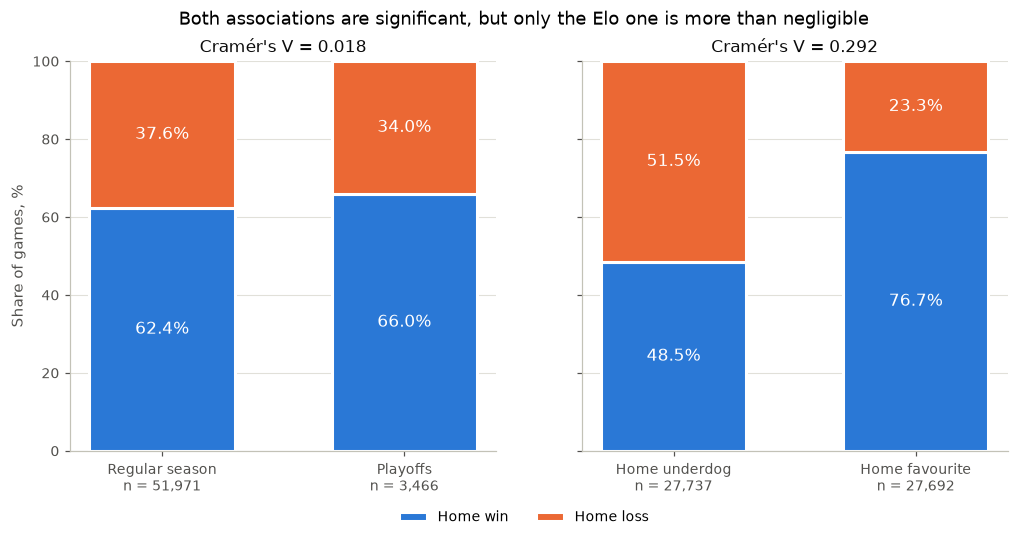

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
panels = [
    (axes[0], home_games, "season_type", ["Regular season", "Playoffs"], tests.loc["season_type x result (main)", "Cramer's V"]),
    (axes[1], rated, "home_elo_status", ["Home underdog", "Home favourite"], tests.loc["Elo status x result", "Cramer's V"]),
]
for ax, data, column, order, v in panels:
    share = pd.crosstab(data[column], data["home_result"], normalize="index").loc[order] * 100
    counts_ = data[column].value_counts().loc[order]
    labels = [f"{o}\nn = {counts_[o]:,}" for o in order]
    win = ax.bar(labels, share["Home win"], color=BLUE, width=0.6, label="Home win", edgecolor="white", linewidth=2)
    loss = ax.bar(labels, share["Home loss"], bottom=share["Home win"], color=ORANGE, width=0.6,
                  label="Home loss", edgecolor="white", linewidth=2)
    for bar, value in zip(win, share["Home win"]):
        ax.text(bar.get_x() + bar.get_width() / 2, value / 2, f"{value:.1f}%", ha="center", va="center", color="white", fontsize=11)
    for bar, base, value in zip(loss, share["Home win"], share["Home loss"]):
        ax.text(bar.get_x() + bar.get_width() / 2, base + value / 2, f"{value:.1f}%", ha="center", va="center", color="white", fontsize=11)
    ax.set_title(f"Cramér's V = {v:.3f}")
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, 100)
axes[0].set_ylabel("Share of games, %")
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Both associations are significant, but only the Elo one is more than negligible", fontsize=12)
save_fig(fig, "fig4_home_result_stacked")
plt.show()

**Interpretation: significance and effect size.**

- **Assumptions:** the smallest expected count is 1,295, far above the usual minimum of 5. Each game is counted once.
- **Main test:** χ² = 17.81, df = 1, p = 2.4 × 10⁻⁵ < 0.05, so **I reject H₀**. Home teams win 66.0% of playoff games and 62.4% of regular-season games.
- **Effect size:** Cramér's V = **0.018**, which is negligible. The result is statistically clear because N = 55,437, but the association is extremely weak. With this sample size a test will detect almost any difference, so p alone cannot tell us whether a difference matters.
- **For comparison:** `era × result` (a 5×2 table, df = 4) is also significant and also negligible (V = 0.036), while `Elo status × result` has V = **0.292**, about the same as the reference example (0.30), which is usually read as a moderate association. On the chart this is obvious: the bars on the left look almost identical, while on the right the home win share goes from 48.5% to 76.7%.

**Is the playoff effect confounded by team strength?** The better-seeded team gets home court in the playoffs, so playoff home teams are stronger on average (`elo_diff` +8.2 vs −1.1). Following standard practice, I stratify by Elo gap and apply the Mantel–Haenszel method.

In [18]:
# Is the playoff effect confounded by team strength? Compare within strata of the pre-game Elo gap.
ELO_STRATA = ["below -100", "-100 to 0", "0 to +100", "above +100"]
home_games["elo_stratum"] = pd.cut(home_games["elo_diff"], [-np.inf, -100, 0, 100, np.inf], labels=ELO_STRATA)

rows, num, den, cmh_diff, cmh_var = {}, 0.0, 0.0, 0.0, 0.0
for stratum in ELO_STRATA:
    part = home_games[home_games["elo_stratum"] == stratum]
    a = ((part["season_type"] == "Playoffs") & (part["home_result"] == "Home win")).sum()
    b = ((part["season_type"] == "Playoffs") & (part["home_result"] == "Home loss")).sum()
    c = ((part["season_type"] == "Regular season") & (part["home_result"] == "Home win")).sum()
    d = ((part["season_type"] == "Regular season") & (part["home_result"] == "Home loss")).sum()
    n = a + b + c + d
    # Mantel-Haenszel pooled odds ratio and the Cochran-Mantel-Haenszel statistic
    num += a * d / n
    den += b * c / n
    cmh_diff += a - (a + b) * (a + c) / n
    cmh_var += (a + b) * (c + d) * (a + c) * (b + d) / (n ** 2 * (n - 1))
    rows[stratum] = {"n playoffs": a + b, "n regular": c + d,
                     "home win % playoffs": 100 * a / (a + b), "home win % regular": 100 * c / (c + d),
                     "gap, p.p.": 100 * a / (a + b) - 100 * c / (c + d), "odds ratio": (a * d) / (b * c),
                     "V in stratum": chi_square_report([[a, b], [c, d]])["Cramer's V"],
                     "p in stratum": chi_square_report([[a, b], [c, d]])["p-value"]}
elo_strata = pd.DataFrame(rows).T
elo_strata.index.name = "elo_diff (home - away)"
save_table(elo_strata, "playoff_effect_within_elo_strata")

crude_or = (table_main.loc["Playoffs", "Home win"] * table_main.loc["Regular season", "Home loss"]) / (
    table_main.loc["Playoffs", "Home loss"] * table_main.loc["Regular season", "Home win"])
mh_or = num / den
cmh_chi2 = cmh_diff ** 2 / cmh_var
print(f"Crude odds ratio (playoffs vs regular): {crude_or:.3f}")
print(f"Mantel-Haenszel odds ratio across Elo strata: {mh_or:.3f}")
print(f"CMH chi2 = {cmh_chi2:.2f}, df = 1, p = {stats.chi2.sf(cmh_chi2, 1):.3g}")
print("Mean elo_diff:", home_games.groupby("season_type")["elo_diff"].mean().round(1).to_dict())
print("Share of home favourites:", (rated.groupby("season_type")["home_elo_status"].apply(lambda s: (s == "Home favourite").mean()) * 100).round(1).to_dict())
# With only two strata the comparison is still confounded inside each stratum
print("Home win % with two coarse strata:")
two_strata = rated.assign(win=rated["home_result"] == "Home win").pivot_table(
    index="home_elo_status", columns="season_type", values="win", aggfunc="mean") * 100
print(two_strata.round(1).to_string())
print("Mean elo_diff of home favourites:", rated[rated["home_elo_status"] == "Home favourite"].groupby("season_type")["elo_diff"].mean().round(1).to_dict())
elo_strata.round(3)

Crude odds ratio (playoffs vs regular): 1.169
Mantel-Haenszel odds ratio across Elo strata: 1.092
CMH chi2 = 5.33, df = 1, p = 0.021
Mean elo_diff: {'Playoffs': 8.2, 'Regular season': -1.1}
Share of home favourites: {'Playoffs': 54.0, 'Regular season': 49.7}
Home win % with two coarse strata:
season_type      Playoffs  Regular season
home_elo_status                          
Home favourite       74.2            76.9
Home underdog        56.4            48.1
Mean elo_diff of home favourites: {'Playoffs': 78.2, 'Regular season': 120.6}


,n playoffs,n regular,home win % playoffs,home win % regular,"gap, p.p.",odds ratio,V in stratum,p in stratum
elo_diff (home - away),,,,,,,,
below -100,465.0,13392.0,44.946,38.635,6.311,1.297,0.023,0.006
-100 to 0,1128.0,12760.0,61.082,57.947,3.135,1.139,0.017,0.041
0 to +100,1302.0,12729.0,70.123,70.053,0.070,1.003,0.000,0.958
above +100,571.0,13090.0,83.363,83.621,-0.259,0.981,0.001,0.870


**Result.**

- **Partial confounding:** the odds ratio falls from **1.169** to **1.092** once the Elo gap is held roughly equal, so a substantial part of the raw playoff effect reflects stronger home teams. A small association remains (CMH χ² = 5.33, p = 0.021).
- **The effect is not the same in all strata:** the playoff advantage exists only when the home team has the *lower* Elo (+6.3 and +3.1 percentage points) and disappears when it has the higher Elo (+0.1 and −0.3). So the pooled odds ratio averages over different situations. A possible explanation, which needs checking: a playoff home team with lower Elo still earned home court through its record, so Elo may underrate it.
- **Number of strata matters:** with only two strata (favourite or underdog) playoff favourites seem to win *less* than regular-season favourites (74.2% vs 76.9%). This apparent reversal mostly goes away with finer strata: playoff favourites are simply less dominant (average Elo gap +78 vs +121). It is a useful warning against reading too much into coarse stratification.

## 5. Explore Several Variables Together

**Variables:** `pts`, `opp_pts`, `margin`, `elo_diff`, `year_id`. Note that `margin` is defined from `pts` and `opp_pts`, so its correlations with them are partly built in by definition, not discovered. `forecast` and post-game Elo are left out: `forecast` is almost the same as `elo_diff` (Part 3), and post-game Elo already contains the result.

The pair plot is built from `matplotlib` panels and is equivalent to `seaborn.pairplot`: histograms on the diagonal, scatterplots below, correlations above.

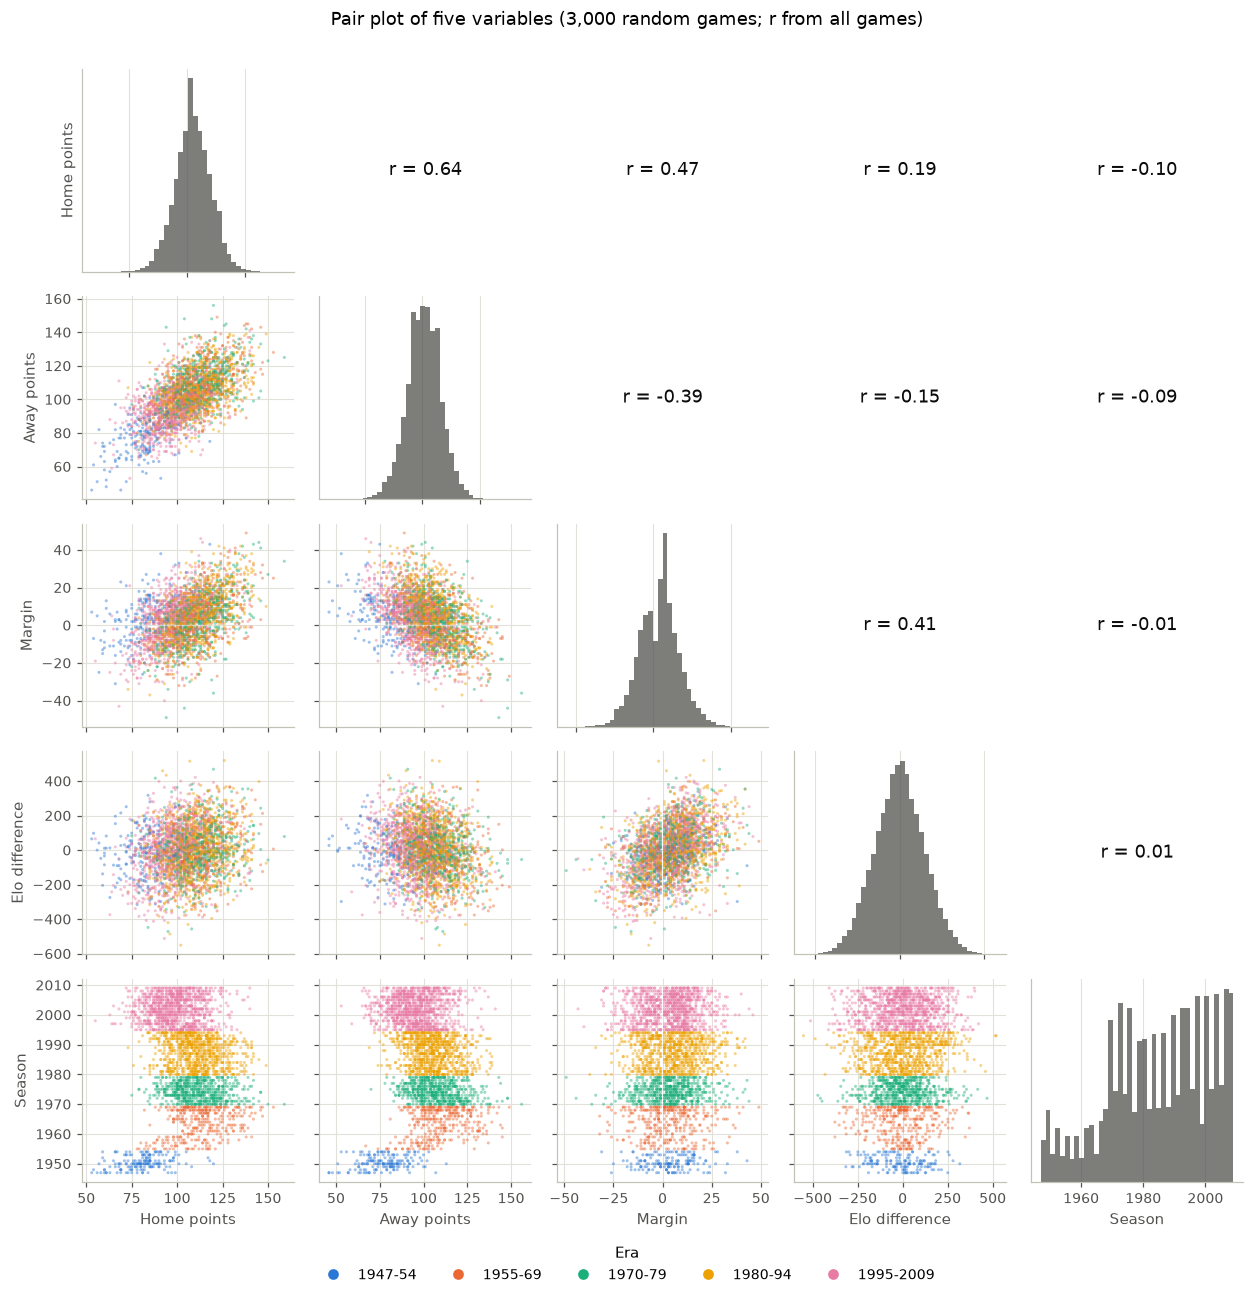

In [19]:
PAIR_VARS = ["pts", "opp_pts", "margin", "elo_diff", "year_id"]
PAIR_LABELS = {"pts": "Home points", "opp_pts": "Away points", "margin": "Margin", "elo_diff": "Elo difference", "year_id": "Season"}
sample = games.sample(3000, random_state=SEED)   # 55,000 points would hide the structure; the correlations use all games
pooled_corr = games[PAIR_VARS].corr()

k = len(PAIR_VARS)
fig, axes = plt.subplots(k, k, figsize=(11.5, 11.5))
colors = sample["era"].astype(str).map(ERA_COLORS)
for i, y in enumerate(PAIR_VARS):
    for j, x in enumerate(PAIR_VARS):
        ax = axes[i, j]
        if i == j:
            ax.hist(games[x], bins=40, color=MUTED, alpha=0.75)
            ax.set_yticks([])
        elif i > j:
            ax.scatter(sample[x], sample[y], s=4, alpha=0.45, c=colors, linewidths=0, rasterized=True)
        else:
            ax.text(0.5, 0.5, f"r = {pooled_corr.loc[y, x]:.2f}", ha="center", va="center", transform=ax.transAxes,
                    fontsize=12, color=INK)
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(False)
            ax.spines[:].set_visible(False)
        if i == k - 1:
            ax.set_xlabel(PAIR_LABELS[x])
        elif i >= j:
            ax.set_xticklabels([])
        if j == 0 and i > 0:
            ax.set_ylabel(PAIR_LABELS[y])
        elif i != j and i > j:
            ax.set_yticklabels([])
axes[0, 0].set_ylabel(PAIR_LABELS[PAIR_VARS[0]])
handles = [Line2D([], [], marker="o", linestyle="", markersize=6, color=ERA_COLORS[e], label=e) for e in ERA_LABELS]
fig.legend(handles=handles, loc="lower center", ncol=5, title="Era", bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Pair plot of five variables (3,000 random games; r from all games)", y=0.995, fontsize=12)
fig.tight_layout(rect=(0, 0.02, 1, 0.99))
save_fig(fig, "fig5_pair_plot")
plt.show()

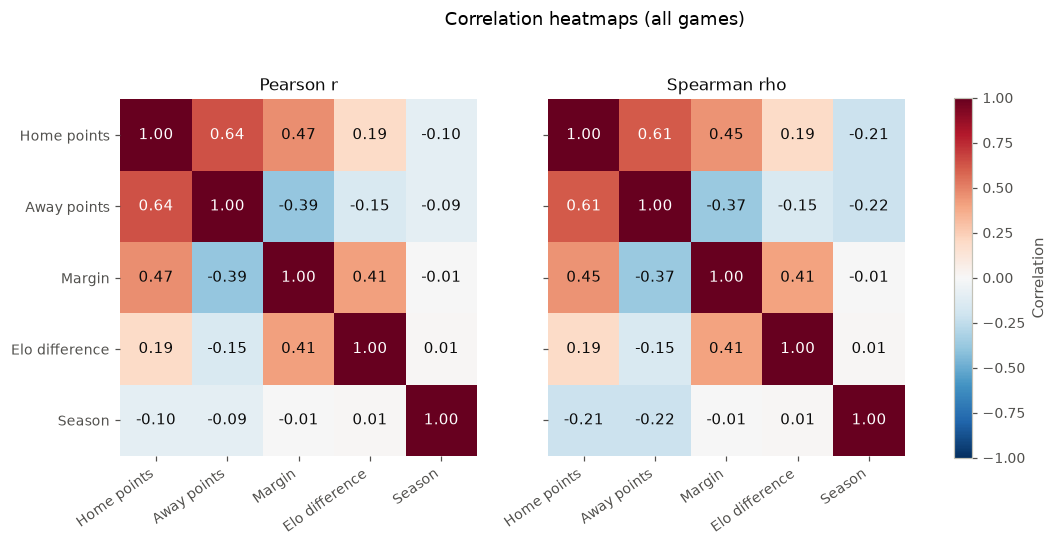

year_id vs pts: r^2 of a straight line = 0.009, share explained by season means = 0.338


,Pearson,Spearman,within season
pair,,,
pts - opp_pts,0.636,0.610,0.446
elo_diff - margin,0.409,0.406,0.410
pts - margin,0.466,0.450,0.562
opp_pts - margin,-0.386,-0.374,-0.489
elo_diff - pts,0.194,0.191,0.238
year_id - pts,-0.097,-0.213,NaN
year_id - elo_diff,0.012,0.012,NaN
year_id - margin,-0.007,-0.007,NaN


In [20]:
spearman_corr = games[PAIR_VARS].rank().corr()
# Season means subtracted: what stays after removing differences between seasons
within_corr = (games[PAIR_VARS[:-1]] - games.groupby("year_id")[PAIR_VARS[:-1]].transform("mean")).corr()

fig, axes = plt.subplots(1, 2, figsize=(11.5, 5), sharey=True)
for ax, matrix, title in [(axes[0], pooled_corr, "Pearson r"), (axes[1], spearman_corr, "Spearman rho")]:
    image = ax.imshow(matrix, cmap="RdBu_r", vmin=-1, vmax=1)
    names = [PAIR_LABELS[v] for v in matrix.columns]
    ax.set_xticks(range(k), names, rotation=35, ha="right")
    ax.set_yticks(range(k), names)
    ax.tick_params(axis="y", labelleft=ax is axes[0])
    ax.grid(False)
    ax.spines[:].set_visible(False)
    for i in range(k):
        for j in range(k):
            value = matrix.iloc[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=10,
                    color="white" if abs(value) > 0.55 else INK)
    ax.set_title(title)
fig.colorbar(image, ax=axes, shrink=0.85, label="Correlation")
fig.suptitle("Correlation heatmaps (all games)", fontsize=12)
save_fig(fig, "fig6_correlation_heatmap")
plt.show()

rows = []
for a, b in [("pts", "opp_pts"), ("elo_diff", "margin"), ("pts", "margin"), ("opp_pts", "margin"), ("elo_diff", "pts"), ("year_id", "pts"), ("year_id", "elo_diff"), ("year_id", "margin")]:
    rows.append({"pair": f"{a} - {b}", "Pearson": pooled_corr.loc[a, b], "Spearman": spearman_corr.loc[a, b],
                 "within season": within_corr.loc[a, b] if a != "year_id" else np.nan})
pair_table = save_table(pd.DataFrame(rows).set_index("pair"), "correlation_pairs")

# How much does the season explain, whatever the shape of the trend?
r2_season = 1 - np.var(residuals(games["pts"].to_numpy(float), season_dummies)) / games["pts"].var(ddof=0)
print(f"year_id vs pts: r^2 of a straight line = {pooled_corr.loc['year_id', 'pts'] ** 2:.3f}, share explained by season means = {r2_season:.3f}")
pair_table.round(3)

**Two interesting relationships.**

1. **`pts` – `opp_pts` (r = 0.64, ρ = 0.61).** The plot shows a tilted ellipse in which the era colours sit in different places along the diagonal. Within seasons it falls to 0.45: the heatmap number alone would not show that part of the correlation comes from mixing eras.
2. **`elo_diff` – `margin` (r = 0.41, ρ = 0.41).** The plot shows a wide tilted band, with colours fully mixed and no visible curve. Within seasons r stays at 0.41. This is the most stable relationship here: the pre-game rating gap really does go along with the result, but single games vary widely.

**A weak relationship: `year_id` – `elo_diff` (r = 0.01).** The plot shows a shapeless cloud centred on zero through all seasons. Here the value and the plot agree: a rating gap is a difference between two teams, so it has no reason to drift with time.

**Comparing visual patterns with correlation values.**

- For the linear pairs the values and pictures agree, and Pearson ≈ Spearman.
- **`year_id` – `pts` is where they disagree:** r = −0.10 looks like "almost nothing", but the plot shows a clear rise and fall, with colours forming distinct bands. A straight line explains 0.9% of the variance and season means explain 33.8%. This is a classic EDA mistake: interpreting a non-linear relationship with Pearson r alone.
- **`pts` – `margin` and `opp_pts` – `margin` become *stronger* within seasons** (0.47 → 0.56 and −0.39 → −0.49). Differences between seasons change the level of scores but not the margin, so they add noise here. Removing them can strengthen a relationship as well as weaken it.

## 6. Principal Component Analysis (PCA)

**Is PCA appropriate?** With caution. The variables are numerical and on very different scales, so standardising is required. I use `pts`, `opp_pts`, `elo_i`, `opp_elo_i`, `year_id`. `margin` and `elo_diff` are left out because they are exact linear combinations of other variables: they add no information, and the last component of such a set has zero variance (checked below).

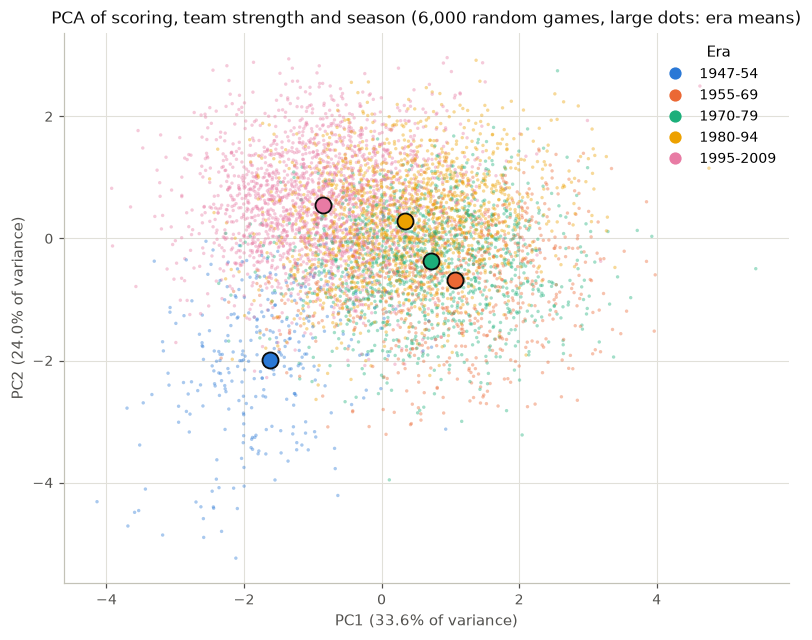

Era means on the components:
            PC1   PC2
1947-54   -1.63 -1.99
1955-69    1.07 -0.68
1970-79    0.72 -0.37
1980-94    0.34  0.29
1995-2009 -0.85  0.54

Correlation of the scores with:
             PC1    PC2    PC3
total_pts  0.972  0.217  0.025
margin     0.051  0.066 -0.572
elo_diff   0.042  0.077 -0.975
year_id   -0.298  0.570 -0.027

Smallest component if margin is added: 0.000000% of variance
     explained variance %  cumulative %
PC1                  33.6          33.6
PC2                  24.0          57.6
PC3                  19.6          77.1
PC4                  17.3          94.5
PC5                   5.5         100.0


,PC1,PC2
pts,0.682,0.201
opp_pts,0.676,0.157
elo_i,-0.087,0.620
opp_elo_i,-0.131,0.529
year_id,-0.230,0.520


In [21]:
PCA_VARS = ["pts", "opp_pts", "elo_i", "opp_elo_i", "year_id"]
X = StandardScaler().fit_transform(games[PCA_VARS])
pca = PCA(random_state=SEED).fit(X)
scores = pca.transform(X)

explained = save_table(pd.DataFrame({"explained variance %": 100 * pca.explained_variance_ratio_,
                                     "cumulative %": 100 * pca.explained_variance_ratio_.cumsum()},
                                    index=[f"PC{i + 1}" for i in range(len(PCA_VARS))]), "pca_explained_variance")
loadings = save_table(pd.DataFrame(pca.components_[:2].T, index=PCA_VARS, columns=["PC1", "PC2"]), "pca_loadings")

rng = np.random.default_rng(SEED)
idx = rng.choice(len(games), 6000, replace=False)
fig, ax = plt.subplots(figsize=(8.5, 6.5))
era_values = games["era"].astype(str).to_numpy()
ax.scatter(scores[idx, 0], scores[idx, 1], s=5, alpha=0.4, c=[ERA_COLORS[e] for e in era_values[idx]], linewidths=0, rasterized=True)
# The era centres show the path of the league through the plane
for era in ERA_LABELS:
    mask = era_values == era
    ax.scatter(scores[mask, 0].mean(), scores[mask, 1].mean(), s=110, color=ERA_COLORS[era], edgecolor=INK, linewidth=1.2, zorder=3)
ax.set_xlabel(f"PC1 ({explained.iloc[0, 0]:.1f}% of variance)")
ax.set_ylabel(f"PC2 ({explained.iloc[1, 0]:.1f}% of variance)")
ax.set_title("PCA of scoring, team strength and season (6,000 random games, large dots: era means)")
handles = [Line2D([], [], marker="o", linestyle="", markersize=7, color=ERA_COLORS[e], label=e) for e in ERA_LABELS]
ax.legend(handles=handles, title="Era", loc="upper right")
save_fig(fig, "fig7_pca")
plt.show()

print("Era means on the components:")
print(pd.DataFrame(scores[:, :2], columns=["PC1", "PC2"]).groupby(era_values).mean().loc[ERA_LABELS].round(2).to_string())
print("\nCorrelation of the scores with:")
print(pd.DataFrame({
    "PC1": [np.corrcoef(scores[:, 0], games[c])[0, 1] for c in ["total_pts", "margin", "elo_diff", "year_id"]],
    "PC2": [np.corrcoef(scores[:, 1], games[c])[0, 1] for c in ["total_pts", "margin", "elo_diff", "year_id"]],
    "PC3": [np.corrcoef(scores[:, 2], games[c])[0, 1] for c in ["total_pts", "margin", "elo_diff", "year_id"]],
}, index=["total_pts", "margin", "elo_diff", "year_id"]).round(3).to_string())
# Why margin stays out: it is an exact linear combination of pts and opp_pts, so its information is already there
with_margin = PCA().fit(StandardScaler().fit_transform(games[PCA_VARS + ["margin"]]))
print(f"\nSmallest component if margin is added: {100 * with_margin.explained_variance_ratio_[-1]:.6f}% of variance")
print(explained.round(1).to_string())
loadings.round(3)

**Explained variance.** PC1 explains 33.6% and PC2 24.0%, together **57.6%**. Four components are needed to pass 90% (94.5%). This is a modest result, and the 2D picture shows only a little over half of the information. With five variables a uniform split would give 20% each, so the data have structure but no single dominant direction. The reason is visible in the heatmap: there is one strongly correlated pair (the two scores), and the other variables are nearly unrelated.

**Interpreting the components.**

- **PC1: scoring level.** Large equal loadings on `pts` and `opp_pts` (0.68), with r = 0.97 between the scores on PC1 and `total_pts`.
- **PC2: overall team rating and time.** Positive loadings on `elo_i` (0.62), `opp_elo_i` (0.53) and `year_id` (0.52). It mixes two ideas, so it is harder to name, and this makes it weaker for interpretation.
- **PC3 (not plotted): strength gap.** r = −0.98 with `elo_diff`. This is important: the information about who is favoured, and therefore about the margin, is **not in the 2D plot**.

**The plot.** Games form one continuous cloud, without separate clusters. Eras overlap, but their centres move along a clear path: 1947–54 sits apart (low scoring, low ratings), then the league moves right in 1955–69 (high scoring) and gradually to the left and up by 1995–2009. This repeats the rise and decline in scoring from Parts 1–3, now combined with rating and time.

**What PCA adds and its limits.** It confirms that scoring level and era are the main structure in these data, and that outcome-related information lies in later components. High variance does not mean high importance for a particular question. PCA also captures only linear structure, and the non-linear `year_id` trend is why the era centres form a curve rather than a straight line.

## 7. Interpretation and New Questions

In [22]:
# Every headline number of Section 7, computed so that the text can be checked against the notebook
key = pd.Series({
    "Playoff - regular gap, mean total points": gap,
    "Same gap with equal era composition": (by_era["Playoffs - Regular"] * weights).sum(),
    "Largest era Cohen's d (absolute)": pairs_era["Cohen's d"].abs().max(),
    "Eta squared of era": eta_squared,
    "ABA - NBA, all seasons": league.loc["All seasons", "ABA - NBA"],
    "ABA - NBA, same seasons": league.loc["Only 1968-1976 (both leagues)", "ABA - NBA"],
    "r(pts, opp_pts) pooled": strata.loc["All games (pooled)", "Pearson r"],
    "r(pts, opp_pts) adjusted for season": adjusted.iloc[3, 0],
    "Cramer's V, season type x result": tests.loc["season_type x result (main)", "Cramer's V"],
    "Cramer's V, Elo status x result": tests.loc["Elo status x result", "Cramer's V"],
    "Crude playoff odds ratio": crude_or,
    "Mantel-Haenszel odds ratio": mh_or,
    "PC1 + PC2, % of variance": explained.iloc[1, 1],
}, name="value")
save_table(key.to_frame(), "key_numbers")
key.round(3).to_frame()

,value
"Playoff - regular gap, mean total points",-4.499
Same gap with equal era composition,-5.103
Largest era Cohen's d (absolute),2.716
Eta squared of era,0.353
"ABA - NBA, all seasons",18.688
"ABA - NBA, same seasons",5.673
"r(pts, opp_pts) pooled",0.636
"r(pts, opp_pts) adjusted for season",0.446
"Cramer's V, season type x result",0.018
"Cramer's V, Elo status x result",0.292


**Main group differences.**

- **Era is the main group variable:** it explains 35% of the variation in total points, with the largest gap between 1947–54 and later eras (d ≈ 2.7), followed by the decline in 1995–2009.
- **Season type changes little:** playoff games have 4.5 fewer points (d = −0.17), and home teams win 3.6 percentage points more. Both are real, and both are small.
- **Spread differs little between groups:** both comparisons are mainly about location, not variability.

**How stratification affected my interpretation.**

| Pooled reading | After stratification |
|---|---|
| `pts`–`opp_pts`, r = 0.64: scores are strongly linked | Within seasons r = 0.45; about half of the shared variance comes from the season |
| ABA scored 18.7 points more than NBA | 5.7 points in the same seasons: most of the gap was about *when* each league played |
| Playoffs have 4.5 fewer points | About −6 since 1970, no measurable gap in 1947–54: the pooled number mixes different situations |
| Home teams do better in the playoffs (OR 1.17) | OR 1.09 after Elo stratification; the effect is limited to home teams with lower Elo |
| `elo_diff`–`margin`, r = 0.41 | Stays stable in all eras and within seasons: stratification also shows what does **not** change |

No relationship fully reversed its direction overall, so I found confounding and effect modification but not a true Simpson's paradox. All my expectations were right in direction. The surprise was that the playoff advantage is limited to home teams with lower Elo.

**What the multivariate analysis added.** Pairwise statistics could not separate shared era effects from game-level effects, whereas partial correlation could. The within-season correlations showed that adjusting can both weaken and strengthen a relationship. PCA showed that the variables form largely separate blocks (scoring, ratings, time), which is why a single summary number is never enough for this dataset.

**Limitations.**

- **Causation:** this is observational data, so all the "explanations" above are hypotheses. The Elo strata remove only part of the strength differences, and season or era are stand-ins for a mix of rules and playing styles.
- **Missing variables:** pace, overtime, injuries and rosters are not in the dataset. They are the most likely explanations for the remaining `pts`–`opp_pts` correlation and cannot be tested here.
- **Independence:** games by the same team in the same season are not fully independent, and playoff games within a series even less so. The p-values are therefore probably too optimistic, which is one more reason to rely on effect sizes.
- **Coding of home games:** the `notes` field shows that 2,653 games (4.8%) coded as home were played at another site, mostly before 1980. The "home" team wins only 54.5% of them, against 62–66% overall, so they are not true home games. Without them the main test does not change its conclusion (χ² = 12.59, p = 3.9 × 10⁻⁴, V = 0.015; 65.9% vs 62.8%). I keep them in the main analysis because the assumption that all notes of this kind mean a neutral site was not verified.
- **Choices I made:** era boundaries and Elo strata are my own, and results such as the two-strata reversal depend on them. Elo itself is computed from past results.

**New research questions.**

1. **Why is the playoff home advantage limited to home teams with lower Elo?** Is Elo underrating teams that earned home court, or does seed or series situation matter? Adding each team's regular-season record and game number in the series would test this.
2. **How much of the remaining within-season correlation (r ≈ 0.45) is explained by pace and overtime?** This needs box-score data with possessions and minutes, joined to this dataset.
3. **When and why did the playoff scoring gap open up?** It is about −6 since 1970 and −2 in 1955–69. Season-by-season analysis could show whether this was a sudden change or a slow one, and whether it is linked to rule changes.
4. **Why has the `pts`–`opp_pts` relationship weakened over time?** A slower and more defence-oriented game, or fewer overtimes? Modelling the slope by season and adding pace data would distinguish these.
5. **Is Elo's forecast equally calibrated across the strata found here,** especially for playoff home underdogs? Comparing `forecast` with real win rates in each stratum would answer this directly.

**Conclusion.** The main lesson is the difference between a pattern in pooled data and a pattern inside groups. Some relationships shrink after stratification, some hold up, and some turn out to apply only in part of the data. A very small p-value did not mean a large effect, and a near-zero correlation did not mean no relationship. Looking at groups, effect sizes and plots together gave a much more careful picture than any single number.